# 07 — Validación temporal retrospectiva

Objetivo: evaluar predicciones para 2023 utilizando exclusivamente
etiquetas de entrenamiento que ya podían conocerse al cierre de 2023.

- Entrenamiento: observaciones hasta 2021.
- Evaluación: observaciones de 2023.
- Resultado observado: actividad en 2024 y 2025.
- Separación adicional por estudiante, reutilizando los cinco folds.
- Preprocesamiento ajustado dentro de cada entrenamiento.

Se comparan logística base, LightGBM base y LightGBM con año.

Esta evaluación es exploratoria: los resultados de 2023 ya fueron
inspeccionados en los notebooks anteriores. No constituye un test
final completamente independiente.

In [49]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

from IPython.display import display
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)
from lightgbm import LGBMClassifier

PROJ_ROOT = Path.cwd()

if PROJ_ROOT.name == "notebooks":
    PROJ_ROOT = PROJ_ROOT.parent

assert (PROJ_ROOT / "src").is_dir()

os.chdir(PROJ_ROOT)

if str(PROJ_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJ_ROOT))

from src.data.load_data import load_processed, load_raw
from src.features.build_features import FEATURES_COLS

with open("configs/config.yaml", encoding="utf-8") as archivo:
    config = yaml.safe_load(archivo)

SEED = int(config["random_seed"])
VENTANA = int(config["target"]["ventana_anios"])
ANIO_EVALUACION = 2023
ULTIMO_ANIO_TRAIN = ANIO_EVALUACION - VENTANA
UMBRAL = 0.50

CLAVES = ["id_alumno", "anio_academico"]

assert (
    ANIO_EVALUACION + VENTANA
    <= int(config["target"]["censurar_hasta"])
)

print("Último año de entrenamiento:", ULTIMO_ANIO_TRAIN)
print("Año evaluado:", ANIO_EVALUACION)

Último año de entrenamiento: 2021
Año evaluado: 2023


In [50]:
df = (
    load_processed()
    .sort_values(CLAVES)
    .reset_index(drop=True)
)

referencia = pd.read_csv(
    "reports/predicciones_baseline_oof.csv"
)

assert not df.duplicated(CLAVES).any()
assert not referencia.duplicated(CLAVES).any()
assert len(df) == len(referencia)

df = df.merge(
    referencia[CLAVES + ["fold", "abandono_real"]],
    on=CLAVES,
    how="left",
    sort=False,
    validate="one_to_one",
)

assert df["fold"].notna().all()
assert df["abandono"].astype(int).eq(df["abandono_real"]).all()

df["fold"] = df["fold"].astype(int)

assert df.groupby("id_alumno")["fold"].nunique().eq(1).all()

edades_originales = load_raw()[CLAVES + ["edad"]].rename(
    columns={"edad": "edad_original"}
)

df = df.merge(
    edades_originales,
    on=CLAVES,
    how="left",
    sort=False,
    validate="one_to_one",
).reset_index(drop=True)

assert df["edad_original"].notna().all()

df["edad"] = df["edad"].astype(float)
df.loc[df["edad_original"].eq(0), "edad"] = np.nan

y = df["abandono"].astype(int)

print("Dataset cargado:", df.shape)

Dataset cargado: (1979, 43)


In [51]:
elegible_train = df["anio_academico"].le(ULTIMO_ANIO_TRAIN)
evaluacion = df["anio_academico"].eq(ANIO_EVALUACION)

assert not (elegible_train & evaluacion).any()

assert (
    df.loc[elegible_train, "anio_academico"] + VENTANA
).le(ANIO_EVALUACION).all()

print("Registros elegibles para entrenamiento:", elegible_train.sum())
print("Registros de evaluación:", evaluacion.sum())

display(
    df.loc[evaluacion, "abandono"]
    .value_counts()
    .sort_index()
    .rename("registros")
)

Registros elegibles para entrenamiento: 969
Registros de evaluación: 589


abandono
0.0    437
1.0    152
Name: registros, dtype: int64

In [52]:
folds_temporales = []
resumen_particiones = []

for fold in sorted(df["fold"].unique()):
    mascara_train = elegible_train & df["fold"].ne(fold)
    mascara_valid = evaluacion & df["fold"].eq(fold)

    idx_train = np.flatnonzero(mascara_train.to_numpy())
    idx_valid = np.flatnonzero(mascara_valid.to_numpy())

    assert len(idx_train) > 0
    assert len(idx_valid) > 0

    alumnos_train = set(df.iloc[idx_train]["id_alumno"])
    alumnos_valid = set(df.iloc[idx_valid]["id_alumno"])

    assert alumnos_train.isdisjoint(alumnos_valid)
    assert y.iloc[idx_train].nunique() == 2
    assert y.iloc[idx_valid].nunique() == 2

    folds_temporales.append((int(fold), idx_train, idx_valid))

    resumen_particiones.append({
        "fold": fold,
        "registros_train": len(idx_train),
        "registros_valid": len(idx_valid),
        "ultimo_anio_train": df.iloc[idx_train]["anio_academico"].max(),
        "anio_validacion": ANIO_EVALUACION,
        "positivos_validacion": int(y.iloc[idx_valid].sum()),
    })

assert len(folds_temporales) == int(config["split"]["n_splits"])

display(pd.DataFrame(resumen_particiones))

,fold,registros_train,registros_valid,ultimo_anio_train,anio_validacion,positivos_validacion
0,1,776,121,2021,2023,31
1,2,778,120,2021,2023,24
2,3,771,115,2021,2023,31
3,4,775,117,2021,2023,40
4,5,776,116,2021,2023,26


In [53]:
X_base = df[FEATURES_COLS].copy()
X_anio = df[FEATURES_COLS + ["anio_academico"]].copy()

logistica = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler()),
    ("modelo", LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=2000,
        class_weight=None,
    )),
])

lightgbm = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("modelo", LGBMClassifier(
        objective="binary",
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=7,
        max_depth=3,
        min_child_samples=30,
        reg_lambda=1.0,
        class_weight=None,
        random_state=SEED,
        n_jobs=2,
        verbosity=-1,
    )),
])

experimentos = {
    "logistica_base": (logistica, X_base),
    "lightgbm_base": (lightgbm, X_base),
    "lightgbm_anio": (clone(lightgbm), X_anio),
}

In [54]:
bloques_predicciones = []

for nombre, (pipeline, X_actual) in experimentos.items():
    probabilidades = np.full(len(df), np.nan)
    veces_evaluado = np.zeros(len(df), dtype=int)

    for fold, idx_train, idx_valid in folds_temporales:
        modelo_fold = clone(pipeline)

        modelo_fold.fit(
            X_actual.iloc[idx_train],
            y.iloc[idx_train],
        )

        probabilidades[idx_valid] = modelo_fold.predict_proba(
            X_actual.iloc[idx_valid]
        )[:, 1]

        veces_evaluado[idx_valid] += 1

        print(f"{nombre} — fold temporal {fold} terminado")

    assert np.isfinite(
        probabilidades[evaluacion.to_numpy()]
    ).all()

    assert (veces_evaluado[evaluacion.to_numpy()] == 1).all()

    salida = df.loc[evaluacion, CLAVES + ["fold"]].copy()
    salida["modelo"] = nombre
    salida["abandono_real"] = y.loc[evaluacion].to_numpy()
    salida["probabilidad_abandono"] = probabilidades[
        evaluacion.to_numpy()
    ]

    bloques_predicciones.append(salida)

predicciones_temporales = pd.concat(
    bloques_predicciones,
    ignore_index=True,
)

assert not predicciones_temporales.duplicated(
    ["modelo"] + CLAVES
).any()

display(predicciones_temporales.groupby("modelo").size())

logistica_base — fold temporal 1 terminado
logistica_base — fold temporal 2 terminado
logistica_base — fold temporal 3 terminado
logistica_base — fold temporal 4 terminado
logistica_base — fold temporal 5 terminado
lightgbm_base — fold temporal 1 terminado
lightgbm_base — fold temporal 2 terminado
lightgbm_base — fold temporal 3 terminado
lightgbm_base — fold temporal 4 terminado
lightgbm_base — fold temporal 5 terminado
lightgbm_anio — fold temporal 1 terminado
lightgbm_anio — fold temporal 2 terminado
lightgbm_anio — fold temporal 3 terminado
lightgbm_anio — fold temporal 4 terminado
lightgbm_anio — fold temporal 5 terminado


modelo
lightgbm_anio     589
lightgbm_base     589
logistica_base    589
dtype: int64

In [55]:
def evaluar_predicciones(grupo):
    real = grupo["abandono_real"].astype(int)
    prob = grupo["probabilidad_abandono"]
    pred = prob.ge(UMBRAL).astype(int)

    return {
        "registros": len(grupo),
        "positivos": int(real.sum()),
        "roc_auc": roc_auc_score(real, prob),
        "average_precision": average_precision_score(real, prob),
        "precision": precision_score(real, pred, zero_division=0),
        "recall": recall_score(real, pred, zero_division=0),
        "alertas": int(pred.sum()),
        "verdaderos_positivos": int(
            (real.eq(1) & pred.eq(1)).sum()
        ),
        "falsos_positivos": int(
            (real.eq(0) & pred.eq(1)).sum()
        ),
        "falsos_negativos": int(
            (real.eq(1) & pred.eq(0)).sum()
        ),
    }


filas = []

for (modelo, fold), grupo in predicciones_temporales.groupby(
    ["modelo", "fold"]
):
    filas.append({
        "modelo": modelo,
        "fold": fold,
        **evaluar_predicciones(grupo),
    })

metricas_temporales_folds = pd.DataFrame(filas)

resumen_temporal = (
    metricas_temporales_folds
    .groupby("modelo")[
        ["roc_auc", "average_precision", "precision", "recall"]
    ]
    .agg(["mean", "std"])
)

display(resumen_temporal.round(4))

roc_auc         average_precision         precision          \
                  mean     std              mean     std      mean     std   
modelo                                                                       
lightgbm_anio   0.7340  0.0440            0.5955  0.0809    0.6606  0.0835   
lightgbm_base   0.7045  0.0448            0.5804  0.0686    0.6382  0.0481   
logistica_base  0.7674  0.0316            0.6357  0.0799    0.7164  0.1144   

                recall          
                  mean     std  
modelo                          
lightgbm_anio   0.3953  0.0677  
lightgbm_base   0.3903  0.0634  
logistica_base  0.4224  0.0485

In [56]:
filas = []

for modelo, grupo in predicciones_temporales.groupby("modelo"):
    filas.append({
        "modelo": modelo,
        **evaluar_predicciones(grupo),
    })

metricas_temporales_globales = pd.DataFrame(filas)

display(metricas_temporales_globales.round(4))

,modelo,registros,positivos,roc_auc,average_precision,precision,recall,alertas,verdaderos_positivos,falsos_positivos,falsos_negativos
0,lightgbm_anio,589,152,0.7418,0.6045,0.6593,0.3947,91,60,31,92
1,lightgbm_base,589,152,0.7145,0.5896,0.6413,0.3882,92,59,33,93
2,logistica_base,589,152,0.7770,0.6377,0.7191,0.4211,89,64,25,88


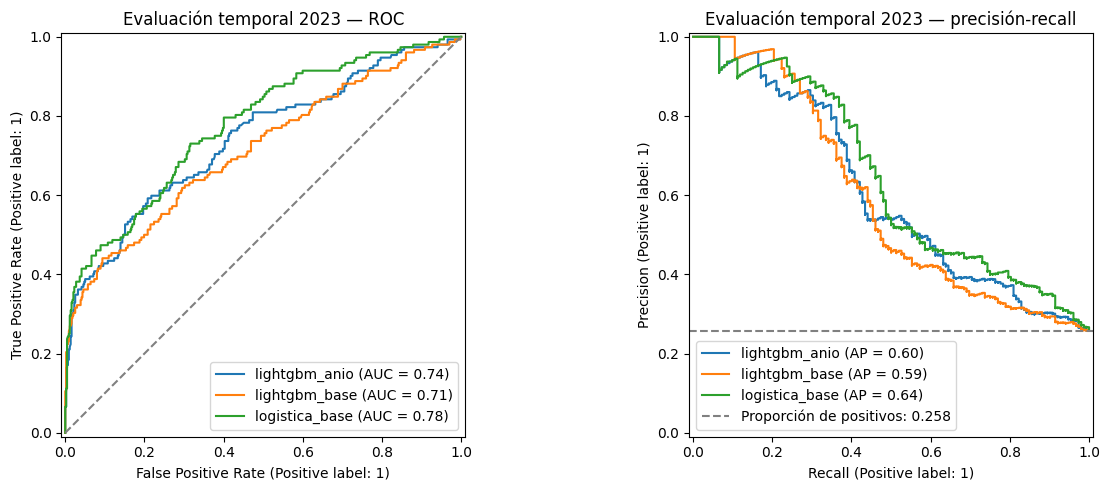

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for modelo, grupo in predicciones_temporales.groupby("modelo"):
    RocCurveDisplay.from_predictions(
        grupo["abandono_real"],
        grupo["probabilidad_abandono"],
        name=modelo,
        ax=axes[0],
    )

    PrecisionRecallDisplay.from_predictions(
        grupo["abandono_real"],
        grupo["probabilidad_abandono"],
        name=modelo,
        ax=axes[1],
    )

axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("Evaluación temporal 2023 — ROC")

prevalencia = y.loc[evaluacion].mean()

axes[1].axhline(
    prevalencia,
    linestyle="--",
    color="gray",
    label=f"Proporción de positivos: {prevalencia:.3f}",
)

axes[1].set_title("Evaluación temporal 2023 — precisión-recall")
axes[1].legend()

plt.tight_layout()
plt.show()

In [58]:
carpeta = PROJ_ROOT / "reports"
carpeta.mkdir(parents=True, exist_ok=True)

metricas_temporales_folds.to_csv(
    carpeta / "metricas_temporales_folds.csv",
    index=False,
)

metricas_temporales_globales.to_csv(
    carpeta / "metricas_temporales_globales.csv",
    index=False,
)

predicciones_temporales.to_csv(
    carpeta / "predicciones_temporales.csv",
    index=False,
)

print("Resultados temporales guardados.")

Resultados temporales guardados.


## Conclusiones de la validación temporal

Se evaluaron 589 estudiantes de 2023, con 152 positivos, entrenando con observaciones hasta 2021 y manteniendo la separación por estudiante. La tabla agrupa las predicciones fuera de muestra; precisión y recall usan corte 0,50.

| Modelo | ROC-AUC | Average Precision | Precisión | Recall |
|---|---:|---:|---:|---:|
| Logística base | **0,7770** | **0,6377** | **71,91 %** | **42,11 %** |
| LightGBM con año | 0,7418 | 0,6045 | 65,93 % | 39,47 % |
| LightGBM base | 0,7145 | 0,5896 | 64,13 % | 38,82 % |

- La logística obtuvo el mejor desempeño en esta prueba temporal, por lo que recupera prioridad como candidata. El año mejoró LightGBM, pero no alcanzó a la logística.
- El recall es insuficiente para detectar la mayoría de los abandonos al corte actual: la logística detectó 64 positivos y dejó pasar 88, con 25 falsas alertas. Corresponde explorar cortes y capacidades de atención, considerando el aumento de falsas alertas.
- Las métricas son menores que en la evaluación anterior, con menos datos de entrenamiento y diferencias observadas entre períodos. Esto no permite atribuir la caída a una única causa ni concluir por sí solo que existe sobreajuste.

**Decisión provisional:** conservar la logística como referencia principal y seguir comparando LightGBM. Antes del despliegue faltan definir la capacidad de atención, validar el umbral, revisar mejoras de variables y calibrar probabilidades. Esta evaluación es exploratoria: 2023 ya había sido inspeccionado, por lo que no constituye un test final independiente.